# ЛР11. Базовая GAN
**Вариант 7.** Сравнение размерности входного шума 32 и 8 на сценах «диск и прямоугольник». Google Colab, стандартная среда CPU.

Гипотеза записана 25.11.2026 в 23:30 МСК до собственного запуска. Восемь координат шума сохранят показатели в пределах 0,5 дБ по `nn_psnr`, 0,10 по `coverage` и 0,05 по `diversity`. На листах ожидаются оба объекта и вариация положения прямоугольника. Сводка преподавателя известна заранее, поэтому это повторение с известным внешним ориентиром.

Сохранённые выходы локального ноутбука восстановлены из проверенного архива повторного прогона 26.11.2026. Исходная история выполнения доступна в [ноутбуке Colab](https://colab.research.google.com/drive/10lnT8sTzH8ta6fUyEaY5nq13s38d1IUb).

In [ ]:
import json
import os
import sys
from pathlib import Path

WORK = Path("/content/lr11")
SOURCE = WORK / "src"
SOURCE.mkdir(parents=True, exist_ok=True)
OUT = WORK / "primary"
os.environ["LAB_THREADS"] = "4"
os.chdir(SOURCE)
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

In [ ]:
%%writefile lab07_lib.py
# ЛР 7. Построение автокодировщика. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128. Внешние данные не нужны: сцены порождаются кодом.
import time
import numpy as np
import torch
import torch.nn as nn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N = 32                      # сторона изображения
SEEDS = range(101, 106)     # серия seed обучения
KINDS = ["disc", "disc_rect", "disc_noise", "disc_color", "two_discs"]   # пять контекстов (наборов данных)
N_FACTORS = {"disc": 3, "disc_rect": 4, "disc_noise": 3, "disc_color": 4, "two_discs": 4}
AMBER, GREEN, PINK = (1.0, 0.76, 0.29), (0.24, 0.86, 0.60), (0.95, 0.35, 0.55)
_YY, _XX = np.mgrid[0:N, 0:N] / (N - 1)


def _disc(img, cx, cy, r, color):
    m = (_XX - cx) ** 2 + (_YY - cy) ** 2 <= r * r
    for k in range(3):
        img[k][m] = color[k]


def _hue(h):
    """Простой цвет по параметру 0..1 (три сдвинутые косинусоиды)."""
    return tuple(0.5 + 0.5 * np.cos(2 * np.pi * (h + s)) for s in (0.0, 1 / 3, 2 / 3))


def render(kind, f):
    """Сцена 3×N×N по вектору факторов f из отрезка [0, 1]: положения и размеры объектов задают изображение однозначно."""
    img = np.zeros((3, N, N), dtype=np.float32)
    img[:] = (0.10 + 0.25 * (_XX + _YY) / 2)[None]
    if kind in ("disc", "disc_noise"):
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], AMBER)
    elif kind == "disc_rect":
        _disc(img, 0.25 + 0.5 * f[0], 0.30 + 0.25 * f[1], 0.12 + 0.08 * f[2], AMBER)
        x0 = int((0.05 + 0.55 * f[3]) * N); img[:, int(0.72 * N):int(0.92 * N), x0:x0 + int(0.3 * N)] = np.array(GREEN)[:, None, None]
    elif kind == "disc_color":
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], _hue(f[3]))
    elif kind == "two_discs":
        _disc(img, 0.15 + 0.3 * f[0], 0.15 + 0.7 * f[1], 0.12, AMBER)
        _disc(img, 0.55 + 0.3 * f[2], 0.15 + 0.7 * f[3], 0.12, PINK)
    else:
        raise ValueError(kind)
    return img


_CACHE = {}


def dataset(kind, n_train=4096, n_test=1024):
    """Обучающая и тестовая выборки (тензоры на устройстве) и факторы. Данные одинаковы для всех запусков (seed 7)."""
    if kind not in _CACHE:
        rng = np.random.default_rng(7)
        f = rng.random((n_train + n_test, N_FACTORS[kind]))
        x = np.stack([render(kind, fi) for fi in f])
        if kind == "disc_noise":
            x = np.clip(x + 0.05 * rng.standard_normal(x.shape).astype(np.float32), 0, 1)
        X = torch.tensor(x, dtype=torch.float32, device=DEVICE); F = torch.tensor(f, dtype=torch.float32, device=DEVICE)
        _CACHE[kind] = (X[:n_train], X[n_train:], F[:n_train], F[n_train:])
    return _CACHE[kind]


class ConvAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, 16, 4, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(),
                                 nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Flatten(), nn.Linear(64 * 16, d))
        self.dec_fc = nn.Sequential(nn.Linear(d, 64 * 16), nn.ReLU())
        self.dec = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(16, 3, 4, 2, 1), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(self.dec_fc(z).view(-1, 64, 4, 4))

    def forward(self, x):
        return self.decode(self.encode(x))


class DenseAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(3 * N * N, 256), nn.ReLU(), nn.Linear(256, d))
        self.dec = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 3 * N * N), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z).view(-1, 3, N, N)

    def forward(self, x):
        return self.decode(self.encode(x))


def build(arch, d):
    return (ConvAE if arch == "conv" else DenseAE)(d).to(DEVICE)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def psnr_images(x, y):
    """Средний по изображениям PSNR, дБ (значения 0..1)."""
    mse = ((x - y) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return float((10 * torch.log10(1.0 / mse)).mean())


def train(model, Xtr, epochs=20, lr=2e-3, loss="mse", noise=0.0, seed=0, batch=128):
    """Обучение с Adam. loss: 'mse' или 'l1'. noise > 0: вход зашумляется (шумоподавляющий автокодировщик), цель — чистое изображение."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = Xtr.shape[0]
    for _ in range(epochs):
        perm = torch.randperm(n, generator=g).to(DEVICE)
        for i in range(0, n, batch):
            x = Xtr[perm[i:i + batch]]
            xin = (x + noise * torch.randn(x.shape, generator=g).to(DEVICE)).clamp(0, 1) if noise > 0 else x
            out = model(xin)
            l = ((out - x) ** 2).mean() if loss == "mse" else (out - x).abs().mean()
            opt.zero_grad(); l.backward(); opt.step()
    return model


@torch.no_grad()
def reconstruct(model, X, eval_noise=0.0, seed=1234):
    model.eval()
    if eval_noise > 0:
        g = torch.Generator(device="cpu").manual_seed(seed)
        X = (X + eval_noise * torch.randn(X.shape, generator=g).to(DEVICE)).clamp(0, 1)
    return model(X)


# Шесть факторов: изменение базового режима A (свёрточный автокодировщик, d = 8, MSE, чистые данные, 4096 примеров).
FACTORS = ["latent_8_to_2", "latent_8_to_32", "arch_conv_to_dense", "loss_mse_to_l1", "input_clean_to_denoising", "train_4096_to_512"]
BASE = dict(arch="conv", d=8, loss="mse", noise=0.0, eval_noise=0.0, n_train=4096, epochs=20)


def settings(factor):
    a, b = dict(BASE), dict(BASE)
    if factor == "latent_8_to_2":
        b["d"] = 2
    elif factor == "latent_8_to_32":
        b["d"] = 32
    elif factor == "arch_conv_to_dense":
        b["arch"] = "dense"
    elif factor == "loss_mse_to_l1":
        b["loss"] = "l1"
    elif factor == "input_clean_to_denoising":
        a["eval_noise"] = b["eval_noise"] = 0.2; b["noise"] = 0.2
    elif factor == "train_4096_to_512":
        b["n_train"] = 512; b["epochs"] = 160   # 512 / 128 * 160 = 640 шагов, как 4096 / 128 * 20: число обновлений весов сохранено
    else:
        raise ValueError(factor)
    return a, b


def run(kind, cfg, seed):
    """Одно обучение: метрики на тестовой выборке."""
    Xtr, Xte, _, _ = dataset(kind)
    Xtr = Xtr[:cfg["n_train"]]
    torch.manual_seed(seed)
    t0 = time.perf_counter()
    model = train(build(cfg["arch"], cfg["d"]), Xtr, cfg["epochs"], loss=cfg["loss"], noise=cfg["noise"], seed=seed)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    p_te = psnr_images(reconstruct(model, Xte, cfg["eval_noise"]), Xte)
    p_tr = psnr_images(reconstruct(model, Xtr[:1024], cfg["eval_noise"]), Xtr[:1024])
    return dict(psnr=p_te, gap=p_tr - p_te, params=n_params(model) / 1000, seconds=dt), model


def variant_summary(n, seeds=SEEDS):
    """Вариант n = 1..30: набор данных c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k])
    A = {m: [] for m in ("psnr", "gap", "params", "seconds")}
    B = {m: [] for m in A}
    run(KINDS[c], a_cfg, 0)  # прогрев
    for s in seeds:
        ma, _ = run(KINDS[c], a_cfg, s)
        mb, _ = run(KINDS[c], b_cfg, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)

In [ ]:
%%writefile lab11_experiment.py
"""Протокол ЛР11 поверх исходных библиотек из учебного комплекта."""
import csv
import hashlib
import json
import math
import os
import platform
import time
from copy import deepcopy
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import numpy as np
import PIL
import torch
from PIL import Image, ImageDraw

import lab11_lib as L


def write_json(path, data):
    temporary = path.with_suffix(".tmp")
    temporary.write_text(json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False) + "\n")
    temporary.replace(path)


def save_sheet(path, images, labels, columns=8):
    tile = 64
    label_height = 22
    rows = math.ceil(len(images) / columns)
    sheet = Image.new("RGB", (columns * tile, rows * (tile + label_height)), "white")
    draw = ImageDraw.Draw(sheet)
    for i, (pixels, label) in enumerate(zip(images, labels, strict=True)):
        row, column = divmod(i, columns)
        x, y = column * tile, row * (tile + label_height)
        image = Image.fromarray(pixels).resize((tile, tile), Image.Resampling.NEAREST)
        sheet.paste(image, (x, y))
        draw.text((x + 4, y + tile + 2), label, fill="#17202a")
    sheet.save(path)


def loss_plot(path, records):
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
    for axis, key, title in zip(
        axes.flat, ("lg", "ld", "d_real", "d_fake"),
        ("Потеря G", "Потеря D", "D на реальных", "D на сгенерированных"), strict=True,
    ):
        for mode, record in records.items():
            values = record["history"][key]
            axis.plot(range(1, record["config"]["steps"] + 1, 10), values, label=mode)
        axis.set_title(title)
        axis.set_xlabel("Шаг обучения")
        axis.grid(alpha=0.25)
        axis.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=135)
    plt.close(fig)


def fit(kind, config, seed, folder, mode, settings, snapshots=()):
    path = folder / f"{mode}_{seed}.json"
    if path.exists():
        return json.loads(path.read_text())
    train, _, _, _ = L.L.dataset(kind)
    started_at = datetime.now(timezone.utc).isoformat()
    saved = {}
    callback_seconds = 0.0

    def snapshot(step, generator):
        nonlocal callback_seconds
        started = time.perf_counter()
        saved[step] = deepcopy(generator)
        callback_seconds += time.perf_counter() - started

    started = time.perf_counter()
    generator, history = L.train_gan(train[:config["n_train"]], config, seed, snapshots, snapshot)
    seconds = time.perf_counter() - started - callback_seconds
    metrics = L.metrics(deepcopy(generator), kind, seed)
    metrics["seconds"] = seconds
    checkpoints = {}
    for step, model in saved.items():
        checkpoints[str(step)] = L.metrics(deepcopy(model), kind, seed)
        images = L.sample(model, settings["samples_per_mode"], settings["sample_seed"])
        images = images.mul(255).round().byte().permute(0, 2, 3, 1).numpy()
        save_sheet(folder / f"{mode}_{seed}_step_{step:04}.png", images,
                   [f"{mode} {i + 1:02d}" for i in range(len(images))])
    record = dict(mode=mode, seed=seed, config=config, started_at=started_at,
                  metrics=metrics, checkpoints=checkpoints, history=history)
    write_json(path, record)
    print(f"{folder.name} {mode} seed {seed}: {seconds:.1f} с", flush=True)
    return record


def run(out, settings, source_dir, *, demo=True):
    out.mkdir(parents=True, exist_ok=True)
    assert L.DEVICE == "cpu", "Выберите CPU в настройках среды Colab."
    kind, a, b = L.variant_settings(settings["variant"])
    assert {key for key in a if a[key] != b[key]} == {"z"}
    assert list(L.SEEDS) == settings["seeds"] and a["steps"] == settings["snapshots"][-1]
    environment = {
        "runtime": "Google Colab CPU" if "COLAB_RELEASE_TAG" in os.environ else "CPU",
        "colab_release_tag": os.environ.get("COLAB_RELEASE_TAG"),
        "python": platform.python_version(), "platform": platform.platform(),
        "torch": str(torch.__version__), "torch_cuda_build": torch.version.cuda,
        "numpy": np.__version__, "pillow": PIL.__version__,
        "matplotlib": matplotlib.__version__, "device": L.DEVICE,
        "available_cpus": len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count(),
        "torch_threads": torch.get_num_threads(), "torch_interop_threads": torch.get_num_interop_threads(),
        "sources_sha256": {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                           for p in sorted(source_dir.glob("*.py"))},
    }
    protocol = dict(settings=settings, kind=kind, configs={"A": a, "B": b}, environment=environment,
                    demo=demo, dataset_seed=7, n_eval=L.N_EVAL, coverage_k=L.K_COVER)
    protocol_path = out / "protocol.json"
    if protocol_path.exists() and json.loads(protocol_path.read_text()) != protocol:
        raise ValueError("Среда или протокол изменились. Выберите новый каталог запуска.")
    write_json(protocol_path, protocol)
    print(json.dumps(environment, ensure_ascii=False, indent=2), flush=True)

    folder = out / "variant07"
    folder.mkdir(exist_ok=True)
    records = []
    for seed in settings["seeds"]:
        for mode, cfg in (("A", a), ("B", b)):
            snapshots = settings["snapshots"] if seed == 101 else ()
            records.append(fit(kind, cfg, seed, folder, mode, settings, snapshots))

    samples = {r["mode"]: r for r in records if r["seed"] == 101}
    loss_plot(out / "training_curves.png", samples)
    _, test, _, _ = L.L.dataset(kind)
    real = test[:32].mul(255).round().byte().permute(0, 2, 3, 1).numpy()
    save_sheet(out / "real_test.png", real, [f"Real {i + 1:02d}" for i in range(len(real))])

    values = {
        mode: {key: [r["metrics"][key] for r in records if r["mode"] == mode] for key in L.METRICS}
        for mode in ("A", "B")
    }
    with (out / "per_seed_metrics.csv").open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=["seed", "mode", *L.METRICS])
        writer.writeheader()
        for record in records:
            writer.writerow(dict(seed=record["seed"], mode=record["mode"], **record["metrics"]))
    rows = []
    reference = {}
    for key, mean_a, spread, mean_b, delta, ratio, exceeds_2s in L.summarize(values["A"], values["B"]):
        tolerance = settings["tolerances"].get(key)
        rows.append(dict(metric=key, A=mean_a, s_A=spread, B=mean_b, delta=delta,
                         abs_delta_over_s=ratio if math.isfinite(ratio) else None, exceeds_2s=exceeds_2s,
                         tolerance=tolerance, exceeds_tolerance=abs(delta) > tolerance if tolerance is not None else None))
        if key in settings["engee_reference"]:
            ref = settings["engee_reference"][key]
            reference[key] = {mode: dict(delta=mean - ref[mode], within_2s=abs(mean - ref[mode]) <= 2 * ref["s_A"])
                              for mode, mean in (("A", mean_a), ("B", mean_b))}
    write_json(out / "metrics.json", rows)
    write_json(out / "engee_comparison.json", reference)

    errors = {
        "one_seed": {"seed101_delta": {key: values["B"][key][0] - values["A"][key][0] for key in L.METRICS},
                     "five_seed_delta": {row["metric"]: row["delta"] for row in rows}},
        "loss_as_quality": {mode: dict(mean_last_10_lg=float(np.mean(r["history"]["lg"][-10:])),
                                       final_metrics=r["metrics"]) for mode, r in samples.items()},
        "unequal_steps": {mode: {step: r["checkpoints"][step] for step in ("700", "1500")}
                          for mode, r in samples.items()},
    }
    write_json(out / "intentional_errors.json", errors)

    if demo:
        folder = out / "demo01"
        folder.mkdir(exist_ok=True)
        demo_kind, demo_a, demo_b = L.variant_settings(settings["demo_variant"])
        for mode, cfg in (("A", demo_a), ("B", demo_b)):
            fit(demo_kind, cfg, 101, folder, mode, settings, settings["snapshots"])

    write_json(out / "passport.json", dict(**protocol, finished_at=datetime.now(timezone.utc).isoformat(),
                                          trainings_variant=len(records), trainings_demo=2 if demo else 0,
                                          status="AWAITING_VISUAL_REVIEW"))
    return rows

In [ ]:
%%writefile lab11_lib.py
# ЛР 11. Базовая GAN. Библиотека учебных функций (ЛР 12 использует её же, добавляя приёмы стабилизации).
# Требуется файл lab07_lib.py из ЛР 7 в той же папке (сцены 32×32, тензоры и устройство берутся оттуда). Внешние данные не нужны.
# Среда получения результатов (20.09.2026): Engee 26.8.2-H3 на процессоре; Python 3.11; torch 2.4.1+cu121.
import os
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import lab07_lib as L

torch.set_num_threads(int(os.environ.get("LAB_THREADS", min(4, torch.get_num_threads()))))   # в Engee по умолчанию видно 112 потоков при 5 ядрах — это замедляет обучение
DEVICE, SEEDS, KINDS = L.DEVICE, L.SEEDS, L.KINDS
N_EVAL = 1024        # число сгенерированных и реальных (тестовых) изображений в оценке
K_COVER = 20         # порядок соседа для радиуса покрытия

# Базовый режим A: обычная (ненасыщающая) GAN. Ключи cfg описаны в train_gan.
BASE = dict(z=32, gw=1.0, bn=True, lr_g=2e-4, lr_d=2e-4, beta1=0.5, loss="nonsat", steps=1500, batch=64,
            n_critic=1, smooth=1.0, noise=0.0, sn=False, gp=10.0, drop=0.0, n_train=4096)


class Gen(nn.Module):
    """Генератор: вектор z → изображение 3×32×32 (полносвязный слой и три транспонированные свёртки)."""
    def __init__(self, z=32, gw=1.0, bn=True):
        super().__init__()
        c1, c2, c3 = max(4, int(64 * gw)), max(4, int(32 * gw)), max(4, int(16 * gw))
        self.c1 = c1
        norm1 = (lambda n: nn.BatchNorm1d(n)) if bn else (lambda n: nn.Identity())
        norm2 = (lambda n: nn.BatchNorm2d(n)) if bn else (lambda n: nn.Identity())
        self.fc = nn.Sequential(nn.Linear(z, c1 * 16), norm1(c1 * 16), nn.ReLU())
        self.net = nn.Sequential(nn.ConvTranspose2d(c1, c2, 4, 2, 1), norm2(c2), nn.ReLU(), nn.ConvTranspose2d(c2, c3, 4, 2, 1), norm2(c3), nn.ReLU(),
                                 nn.ConvTranspose2d(c3, 3, 4, 2, 1), nn.Sigmoid())

    def forward(self, z):
        return self.net(self.fc(z).view(-1, self.c1, 4, 4))


class Disc(nn.Module):
    """Дискриминатор (критик): изображение → одно число (логит). sn — спектральная нормализация всех слоёв."""
    def __init__(self, sn=False, drop=0.0):
        super().__init__()
        w = (lambda m: nn.utils.spectral_norm(m)) if sn else (lambda m: m)
        self.net = nn.Sequential(w(nn.Conv2d(3, 16, 4, 2, 1)), nn.LeakyReLU(0.2), nn.Dropout(drop), w(nn.Conv2d(16, 32, 4, 2, 1)), nn.LeakyReLU(0.2), nn.Dropout(drop),
                                 w(nn.Conv2d(32, 64, 4, 2, 1)), nn.LeakyReLU(0.2), nn.Dropout(drop), nn.Flatten(), w(nn.Linear(64 * 16, 1)))

    def forward(self, x):
        return self.net(x).squeeze(1)


def _grad_penalty(d, real, fake):
    a = torch.rand(real.shape[0], 1, 1, 1)
    x = (a * real + (1 - a) * fake).requires_grad_(True)
    g = torch.autograd.grad(d(x).sum(), x, create_graph=True)[0]
    return ((g.flatten(1).norm(dim=1) - 1) ** 2).mean()


def train_gan(Xtr, cfg, seed, snapshots=(), on_snapshot=None):
    """Обучение GAN. Ключи cfg: z, gw (ширина генератора), bn (нормализация в генераторе), lr_g, lr_d, beta1, loss ('nonsat' — ненасыщающая,
    'sat' — исходная минимаксная, 'wgan' — критик Вассерштейна со штрафом за градиент), steps, batch, n_critic (шагов D на один шаг G),
    smooth (целевое значение для реальных, 1.0 — без сглаживания), noise (СКО шума на входе D, линейно убывает до 0), sn (спектральная нормализация D), drop (доля отключаемых нейронов в D), gp (вес штрафа),
    n_train (число обучающих изображений; используется в run).
    snapshots — номера шагов, на которых вызывается on_snapshot(step, G). Возвращает генератор и словарь диагностики."""
    torch.manual_seed(seed)
    g_rng = torch.Generator(device="cpu").manual_seed(seed)
    G, D = Gen(cfg["z"], cfg["gw"], cfg["bn"]).to(DEVICE), Disc(cfg["sn"], cfg["drop"]).to(DEVICE)
    betas = (0.0, 0.9) if cfg["loss"] == "wgan" else (cfg["beta1"], 0.999)
    og = torch.optim.Adam(G.parameters(), cfg["lr_g"], betas=betas)
    od = torch.optim.Adam(D.parameters(), cfg["lr_d"], betas=betas)
    n, B, steps = Xtr.shape[0], cfg["batch"], cfg["steps"]
    hist = dict(d_real=[], d_fake=[], lg=[], ld=[])
    for step in range(steps):
        sigma = cfg["noise"] * (1 - step / steps)
        for _ in range(cfg["n_critic"]):
            idx = torch.randint(0, n, (B,), generator=g_rng)
            real = Xtr[idx]
            with torch.no_grad():
                fake = G(torch.randn(B, cfg["z"], generator=g_rng))
            xr, xf = real, fake
            if sigma > 0:
                xr = real + sigma * torch.randn(real.shape, generator=g_rng); xf = fake + sigma * torch.randn(fake.shape, generator=g_rng)
            dr, df = D(xr), D(xf)
            if cfg["loss"] == "wgan":
                ld = df.mean() - dr.mean() + cfg["gp"] * _grad_penalty(D, real, fake)
            else:
                ld = F.binary_cross_entropy_with_logits(dr, torch.full_like(dr, cfg["smooth"])) + F.binary_cross_entropy_with_logits(df, torch.zeros_like(df))
            od.zero_grad(); ld.backward(); od.step()
        fake = G(torch.randn(B, cfg["z"], generator=g_rng))
        xf = fake + sigma * torch.randn(fake.shape, generator=g_rng) if sigma > 0 else fake
        dfk = D(xf)
        if cfg["loss"] == "wgan":
            lg = -dfk.mean()
        elif cfg["loss"] == "sat":
            lg = -F.binary_cross_entropy_with_logits(dfk, torch.zeros_like(dfk))     # минимизируем log(1 − D(G(z)))
        else:
            lg = F.binary_cross_entropy_with_logits(dfk, torch.ones_like(dfk))       # максимизируем log D(G(z))
        og.zero_grad(); lg.backward(); og.step()
        if step % 10 == 0:
            hist["ld"].append(ld.item()); hist["lg"].append(lg.item())
            hist["d_real"].append(float(torch.sigmoid(dr).mean())); hist["d_fake"].append(float(torch.sigmoid(df).mean()))
        if on_snapshot is not None and (step + 1) in snapshots:
            on_snapshot(step + 1, G)
    return G, hist


@torch.no_grad()
def sample(G, n=N_EVAL, seed=1000, z=None):
    """n изображений; нормализация в генераторе работает по статистике пакета (как при обучении), пакеты по 256."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    zdim = G.fc[0].in_features
    out = [G(torch.randn(min(256, n - i), zdim, generator=g)) for i in range(0, n, 256)]
    return torch.cat(out)


@torch.no_grad()
def metrics(G, kind, seed=0):
    """Показатели на 1024 сгенерированных и 1024 тестовых изображениях, в пространстве пикселей.
    nn_psnr — средний PSNR (дБ) между сгенерированным изображением и ближайшим тестовым: правдоподобие каждой картинки (выше — лучше);
    coverage — доля тестовых изображений, в шар радиуса «расстояние до 20-го соседа среди тестовых» вокруг которых попало хотя бы одно сгенерированное (Naeem и др., 2020): охват разнообразия;
    diversity — среднее попарное расстояние между сгенерированными, делённое на такое же для тестовых (1 — как у данных)."""
    Xte = L.dataset(kind)[1][:N_EVAL]
    fake = sample(G, N_EVAL, 1000 + seed)
    fr, ff = Xte.flatten(1), fake.flatten(1)
    d_rf = torch.cdist(ff, fr)
    nn_psnr = float((10 * torch.log10(1.0 / (d_rf.min(1).values ** 2 / fr.shape[1]).clamp_min(1e-10))).mean())
    d_rr = torch.cdist(fr, fr)
    radius = d_rr.fill_diagonal_(float("inf")).kthvalue(K_COVER, dim=1).values
    coverage = float((d_rf.min(0).values < radius).float().mean())
    d_rr = d_rr.masked_fill(torch.isinf(d_rr), 0.0)
    div = float(torch.cdist(ff, ff).mean() / d_rr.mean())
    return dict(nn_psnr=nn_psnr, coverage=coverage, diversity=div)


def run(kind, cfg, seed):
    """Одно обучение и оценка."""
    Xtr = L.dataset(kind)[0][:cfg["n_train"]]
    t0 = time.perf_counter()
    G, hist = train_gan(Xtr, cfg, seed)
    dt = time.perf_counter() - t0
    m = metrics(G, kind, seed)
    m["seconds"] = dt
    return m, G, hist


# Шесть факторов ЛР 11: изменение базового режима A.
FACTORS = ["z_32_to_8", "gwidth_1_to_0.5", "lr_2e-4_to_1e-3", "beta1_0.5_to_0.9", "bn_on_to_off", "loss_nonsat_to_sat"]


def settings(factor):
    a, b = dict(BASE), dict(BASE)
    if factor == "z_32_to_8":
        b["z"] = 8
    elif factor == "gwidth_1_to_0.5":
        b["gw"] = 0.5
    elif factor == "lr_2e-4_to_1e-3":
        b["lr_g"] = b["lr_d"] = 1e-3
    elif factor == "beta1_0.5_to_0.9":
        b["beta1"] = 0.9
    elif factor == "bn_on_to_off":
        b["bn"] = False
    elif factor == "loss_nonsat_to_sat":
        b["loss"] = "sat"
    else:
        raise ValueError(factor)
    return a, b


_CACHE = {}


def cached_run(kind, cfg, seed):
    """Обучение выполняется один раз для каждой комбинации (набор данных, конфигурация, seed): режим A общий для шести факторов."""
    key = (kind, tuple(sorted(cfg.items())), seed)
    if key not in _CACHE:
        _CACHE[key] = run(kind, cfg, seed)[0]
    return _CACHE[key]


def summarize(A, B):
    """Для каждой метрики: среднее A, s (по seed режима A), среднее B, разность, |d|/s, признак |d| > 2s."""
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return rows


def variant_settings(n):
    """Вариант n = 1..30: набор данных c = (n-1)//6, фактор k = (n-1)%6. Возвращает (набор, конфигурация A, конфигурация B)."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k])
    return KINDS[c], a_cfg, b_cfg


METRICS = ("nn_psnr", "coverage", "diversity", "seconds")


def variant_summary(n, seeds=SEEDS):
    """Вариант n = 1..30: для каждой метрики — A, s, B, разность, |d|/s, признак |d| > 2s (по seed)."""
    kind, a_cfg, b_cfg = variant_settings(n)
    A = {m: [] for m in METRICS}
    B = {m: [] for m in METRICS}
    for s in seeds:
        ma, mb = cached_run(kind, a_cfg, s), cached_run(kind, b_cfg, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    return dict(variant=n, ctx=(n - 1) // 6 + 1, factor=FACTORS[(n - 1) % 6], rows=summarize(A, B))

In [ ]:
import hashlib

EXPECTED = {'lab07_lib.py': 'd84b83a878f55e95289d76a788dc9fa84d3249d0d33aa719d9db8d6792fd2698', 'lab11_experiment.py': 'b35a5ca45af27f522c440cf8f5e8ca6c64af78815d39c9bf94e441e3bc61ef9a', 'lab11_lib.py': '88b6083ffa28bd26ce2c6f4e9c142babae7398eb89185636aaa3207dfe7f396b'}
for name, digest in EXPECTED.items():
    actual = hashlib.sha256((SOURCE / name).read_bytes()).hexdigest()
    assert actual == digest, (name, actual)
    print(name, actual)
SETTINGS = json.loads('{\n  "variant": 7,\n  "demo_variant": 1,\n  "environment": "Google Colab CPU",\n  "threads": 4,\n  "seeds": [101, 102, 103, 104, 105],\n  "snapshots": [100, 300, 700, 1500],\n  "sample_seed": 7,\n  "samples_per_mode": 32,\n  "hypothesis_recorded_at": "2026-11-25T23:30:00+03:00",\n  "tolerances": {"nn_psnr": 0.5, "coverage": 0.10, "diversity": 0.05},\n  "engee_reference": {\n    "nn_psnr": {"A": 19.25, "s_A": 0.48, "B": 19.23},\n    "coverage": {"A": 0.882, "s_A": 0.103, "B": 0.872},\n    "diversity": {"A": 0.950, "s_A": 0.009, "B": 0.952}\n  }\n}\n')
assert SETTINGS["threads"] == int(os.environ["LAB_THREADS"])

## Обучение
Выполняются десять обучений варианта 7 и два диагностических обучения демонстрационного варианта 1. Для повторения в новом сеансе задайте `OUT = WORK / "repeat_session"` и `RUN_DEMO = False`. Внутри одного сеанса повтор ячейки продолжает расчёт по сохранённым JSON.

In [ ]:
from IPython.display import display, Image, Markdown
import lab11_experiment as experiment

RUN_DEMO = True
rows = experiment.run(OUT, SETTINGS, SOURCE, demo=RUN_DEMO)
header = "| Метрика | A | s(A) | B | B−A | 2s | Больше допуска |"
table = [header, "|---|---:|---:|---:|---:|:---:|:---:|"]
def flag(value):
    return "да" if value else "нет" if value is not None else "—"
for row in rows:
    table.append(
        f"| {row['metric']} | {row['A']:.4f} | {row['s_A']:.4f} | "
        f"{row['B']:.4f} | {row['delta']:+.4f} | {flag(row['exceeds_2s'])} | {flag(row['exceeds_tolerance'])} |"
    )
display(Markdown("\n".join(table)))

{
  "runtime": "Google Colab CPU",
  "colab_release_tag": "release-colab-external-images_20261118-060058_RC00",
  "python": "3.13.18",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch": "2.14.1+cpu",
  "torch_cuda_build": null,
  "numpy": "2.4.6",
  "pillow": "11.3.0",
  "matplotlib": "3.10.0",
  "device": "cpu",
  "available_cpus": 2,
  "torch_threads": 4,
  "torch_interop_threads": 1,
  "sources_sha256": {
    "lab07_lib.py": "d84b83a878f55e95289d76a788dc9fa84d3249d0d33aa719d9db8d6792fd2698",
    "lab11_experiment.py": "b35a5ca45af27f522c440cf8f5e8ca6c64af78815d39c9bf94e441e3bc61ef9a",
    "lab11_lib.py": "88b6083ffa28bd26ce2c6f4e9c142babae7398eb89185636aaa3207dfe7f396b"
  }
}


| Метрика | A | s(A) | B | B−A | 2s | Больше допуска |
|---|---:|---:|---:|---:|:---:|:---:|
| nn_psnr | 19.3224 | 0.4883 | 19.3253 | +0.0028 | нет | нет |
| coverage | 0.8984 | 0.1041 | 0.8973 | -0.0012 | нет | нет |
| diversity | 0.9499 | 0.0121 | 0.9543 | +0.0045 | нет | нет |
| seconds | 203.1157 | 7.1901 | 199.0665 | -4.0492 | нет | — |

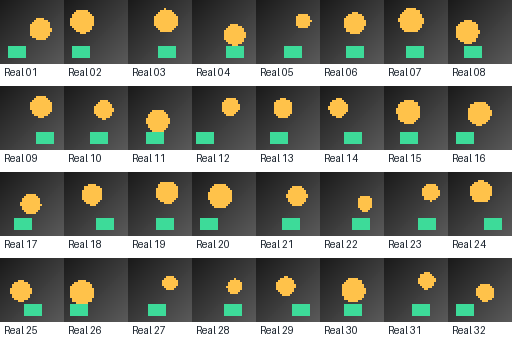

A_101_step_0100.png


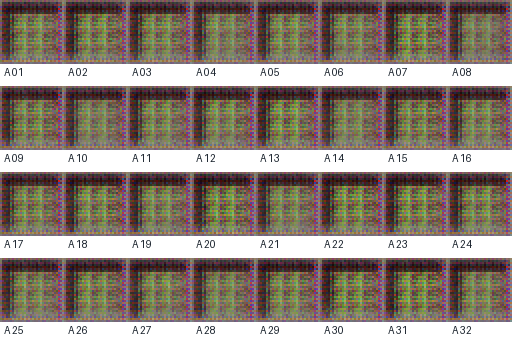

A_101_step_0300.png


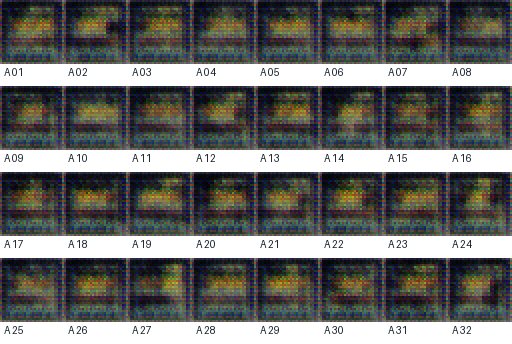

A_101_step_0700.png


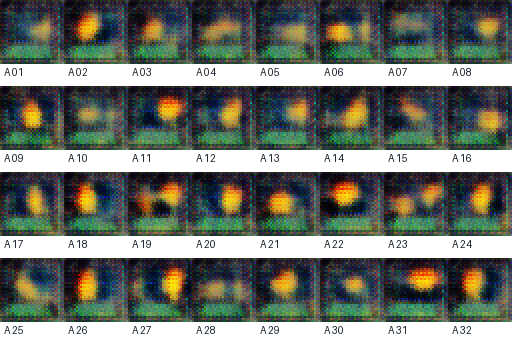

A_101_step_1500.png


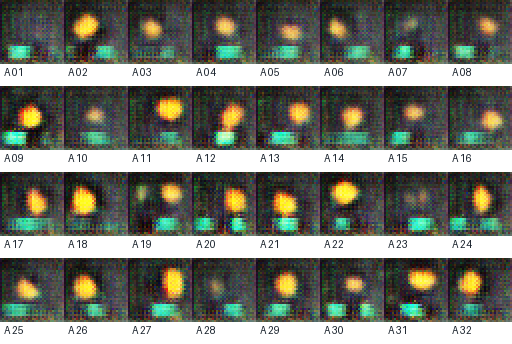

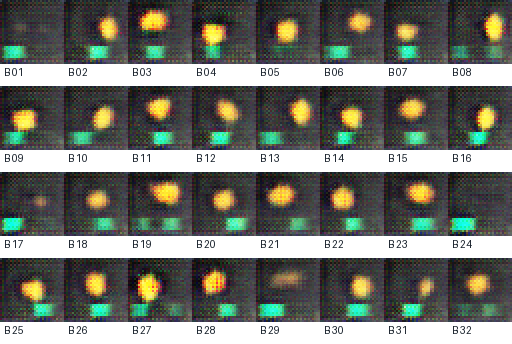

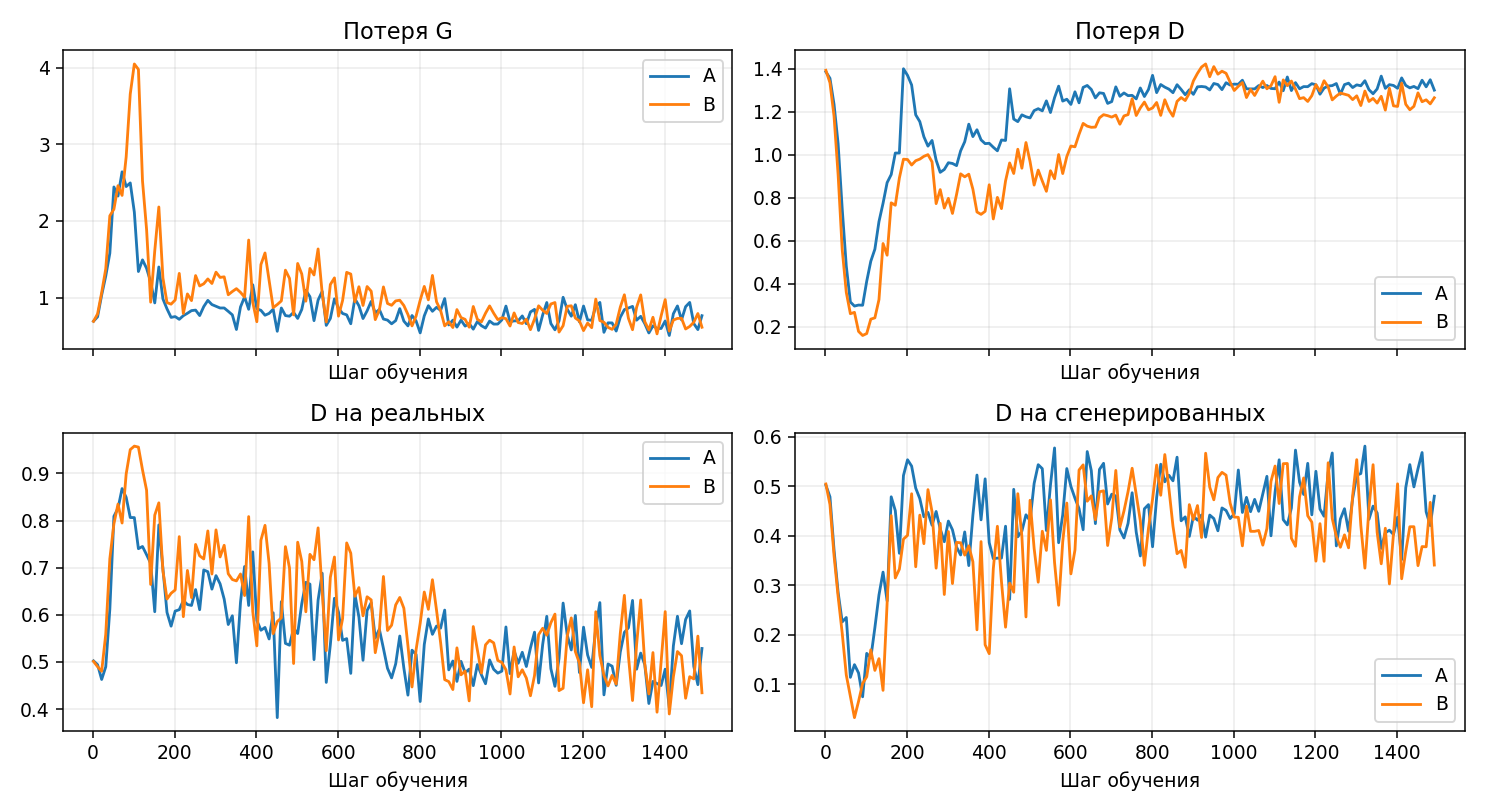

In [ ]:
display(Image(filename=str(OUT / "real_test.png")))
for path in sorted((OUT / "variant07").glob("A_101_step_*.png")):
    print(path.name)
    display(Image(filename=str(path)))
display(Image(filename=str(OUT / "variant07/B_101_step_1500.png")))
display(Image(filename=str(OUT / "training_curves.png")))

## Визуальная оценка
Просмотрите листы. Запишите 3–4 конкретных наблюдения о форме, положении объектов, заметности прямоугольника, повторах и артефактах. Отдельно опишите динамику A по четырём шагам. В архиве собираются журналы, метрики, паспорт и все изображения.

In [ ]:
from datetime import datetime, timezone
from shutil import make_archive

VISUAL_CHECK = {"mode_A": "", "mode_B": "", "dynamics_A": "", "comparison": ""}
passport_path = OUT / "passport.json"
if all(note.strip() for note in VISUAL_CHECK.values()):
    experiment.write_json(OUT / "visual_check.json", VISUAL_CHECK)
    passport = json.loads(passport_path.read_text())
    passport["status"] = "COMPLETE"
    passport["visual_reviewed_at"] = datetime.now(timezone.utc).isoformat()
    experiment.write_json(passport_path, passport)
else:
    print("Визуальная оценка остаётся открытой. Архив содержит результаты обучения.")
archive = make_archive(str(WORK / f"lr11_{OUT.name}"), "zip", OUT)
print(archive)

In [ ]:
from google.colab import files

files.download(archive)